# **Day 91: Vector Data - Points, Lines and Polygons**

GIS data comes in two main types:

| | Vector data | Raster data |
|---|---|---|
| What it is | Shapes made of **points and lines** | A **grid of pixels** |
| Examples | Schools, roads, rivers, district boundaries | Satellite images, elevation (DEM), rainfall maps |
| File formats | Shapefile, GeoJSON, GeoPackage | GeoTIFF, ASCII grid |

Today we work with **vector data**. There are three basic shapes (geometries):
- **Point:** One location (a school, a tube well, a GPS point).
- **Line (LineString):** Points joined in order (a road, a river).
- **Polygon:** A closed area (a district, a lake, a farm field).

We will write the important GIS operations **ourselves**, so that we understand how GIS software works inside. (On Day 99, we will see the library **Shapely**, which does all of this in one line each.)

In [1]:
import math
import json
import numpy as np
import matplotlib.pyplot as plt

## **Our Study Area**
A **study area** near **Midnapore** town, a part of the **Kangsabati river**, and some villages. (The shapes are simplified and made up for practice. The coordinates are in the real area.)

In [2]:
study_area = [   # Polygon corners (lat, lon)
    (22.460, 87.270), (22.465, 87.330), (22.440, 87.375), (22.395, 87.370),
    (22.380, 87.320), (22.400, 87.275),
]
river = [        # A line (lat, lon), flowing from west to east
    (22.405, 87.250), (22.410, 87.285), (22.402, 87.315), (22.410, 87.345), (22.398, 87.390),
]
villages = {     # Points (lat, lon)
    "Village A": (22.448, 87.300),
    "Village B": (22.420, 87.350),
    "Village C": (22.412, 87.300),
    "Village D": (22.470, 87.360),
    "Village E": (22.385, 87.260),
    "Village F": (22.430, 87.325),
}

## **Step 1: Project to Metres (UTM Zone 45N)**
As we learned on Day 90, we must project the coordinates into **metres** before measuring anything. We use the same UTM formula.

In [3]:
def latlon_to_utm(lat, lon, zone=45):
    a, f, k0 = 6378137.0, 1 / 298.257223563, 0.9996
    e2 = f * (2 - f); ep2 = e2 / (1 - e2); e4, e6 = e2 ** 2, e2 ** 3
    lon0 = math.radians((zone - 1) * 6 - 180 + 3)
    phi, lam = math.radians(lat), math.radians(lon)
    N = a / math.sqrt(1 - e2 * math.sin(phi) ** 2)
    T, C, A = math.tan(phi) ** 2, ep2 * math.cos(phi) ** 2, math.cos(phi) * (lam - lon0)
    M = a * ((1 - e2/4 - 3*e4/64 - 5*e6/256) * phi - (3*e2/8 + 3*e4/32 + 45*e6/1024) * math.sin(2*phi)
             + (15*e4/256 + 45*e6/1024) * math.sin(4*phi) - (35*e6/3072) * math.sin(6*phi))
    x = k0 * N * (A + (1 - T + C) * A**3 / 6 + (5 - 18*T + T*T + 72*C - 58*ep2) * A**5 / 120) + 500000
    y = k0 * (M + N * math.tan(phi) * (A*A/2 + (5 - T + 9*C + 4*C*C) * A**4 / 24
                                        + (61 - 58*T + T*T + 600*C - 330*ep2) * A**6 / 720))
    return x, y

area_xy = [latlon_to_utm(*p) for p in study_area]
river_xy = [latlon_to_utm(*p) for p in river]
village_xy = {name: latlon_to_utm(*p) for name, p in villages.items()}
print("First corner in UTM:", [round(v, 1) for v in area_xy[0]])

First corner in UTM: [527778.9, 2483768.9]


## **Step 2: Length of a Line**
The length of a line = the sum of the straight distances between each pair of neighbouring points.

In [4]:
def line_length(points):
    return sum(math.dist(p, q) for p, q in zip(points, points[1:]))

print(f"River length in the study area: {line_length(river_xy) / 1000:.2f} km")

River length in the study area: 14.89 km


## **Step 3: Area, Perimeter and Centroid of a Polygon**
- **Area:** Shoelace formula (Day 45).
- **Perimeter:** The length of the boundary line, including the side that closes the shape.
- **Centroid:** The "centre of mass" of the shape. GIS software uses it to place labels.

In [5]:
def polygon_area(pts):
    s = sum(x1 * y2 - x2 * y1 for (x1, y1), (x2, y2) in zip(pts, pts[1:] + pts[:1]))
    return abs(s) / 2

def polygon_perimeter(pts):
    return line_length(pts + pts[:1])            # Add the first point again to close it

def polygon_centroid(pts):
    a = cx = cy = 0
    for (x1, y1), (x2, y2) in zip(pts, pts[1:] + pts[:1]):
        cross = x1 * y2 - x2 * y1
        a += cross
        cx += (x1 + x2) * cross
        cy += (y1 + y2) * cross
    a /= 2
    return cx / (6 * a), cy / (6 * a)

area_m2 = polygon_area(area_xy)
print(f"Area      : {area_m2 / 1e6:.2f} square km = {area_m2 / 1e4:,.0f} hectare")
print(f"Perimeter : {polygon_perimeter(area_xy) / 1000:.2f} km")
print(f"Centroid  : {[round(v) for v in polygon_centroid(area_xy)]} (UTM metres)")

Area      : 79.17 square km = 7,917 hectare
Perimeter : 33.80 km
Centroid  : [533041, 2479827] (UTM metres)


## **Step 4: Is a Point Inside the Polygon? (Ray Casting)**
This is one of the most used operations in GIS. The trick is simple:

**Draw an imaginary line from the point towards the right. Count how many times it crosses the polygon's boundary.**
- **Odd** number of crossings -> the point is **inside**.
- **Even** number of crossings -> the point is **outside**.

In [6]:
def point_in_polygon(point, polygon):
    x, y = point
    inside = False
    for (x1, y1), (x2, y2) in zip(polygon, polygon[1:] + polygon[:1]):
        if (y1 > y) != (y2 > y):                               # The edge crosses the horizontal line through the point
            x_cross = x1 + (y - y1) * (x2 - x1) / (y2 - y1)    # Where it crosses
            if x < x_cross:                                    # The crossing is to the right of the point
                inside = not inside
    return inside

for name, p in village_xy.items():
    print(f"{name}: {'INSIDE' if point_in_polygon(p, area_xy) else 'outside'} the study area")

Village A: INSIDE the study area
Village B: INSIDE the study area
Village C: INSIDE the study area
Village D: outside the study area
Village E: outside the study area
Village F: INSIDE the study area


Let us understand the code above:
- We check every edge of the polygon.
- `(y1 > y) != (y2 > y)` is True only when the edge goes **across** the point's height.
- Each crossing on the right side **flips** `inside` between True and False. So after an odd number of flips, it is True.

## **Step 5: Distance from a Point to a Line**
How far is each village from the river? We find the **shortest** distance from the point to every segment of the river line, and take the smallest.

In [7]:
def point_to_segment(p, a, b):
    (px, py), (ax, ay), (bx, by) = p, a, b
    dx, dy = bx - ax, by - ay
    t = ((px - ax) * dx + (py - ay) * dy) / (dx * dx + dy * dy)
    t = max(0, min(1, t))                  # Stay within the segment
    nearest = (ax + t * dx, ay + t * dy)
    return math.dist(p, nearest)

def point_to_line(p, line):
    return min(point_to_segment(p, a, b) for a, b in zip(line, line[1:]))

for name, p in village_xy.items():
    print(f"{name}: {point_to_line(p, river_xy) / 1000:.2f} km from the river")

Village A: 4.47 km from the river
Village B: 1.21 km from the river
Village C: 0.64 km from the river
Village D: 6.82 km from the river
Village E: 2.34 km from the river
Village F: 2.70 km from the river


## **Step 6: Buffer Analysis**
A **buffer** is a zone of a fixed distance around a feature. For example, "all villages within **1 km** of the river may be at risk of flooding".

In [8]:
BUFFER_M = 1000
at_risk = [name for name, p in village_xy.items()
           if point_in_polygon(p, area_xy) and point_to_line(p, river_xy) <= BUFFER_M]
print(f"Villages inside the study area and within {BUFFER_M} m of the river:", at_risk)

Villages inside the study area and within 1000 m of the river: ['Village C']


## **Step 7: Drawing the Map**

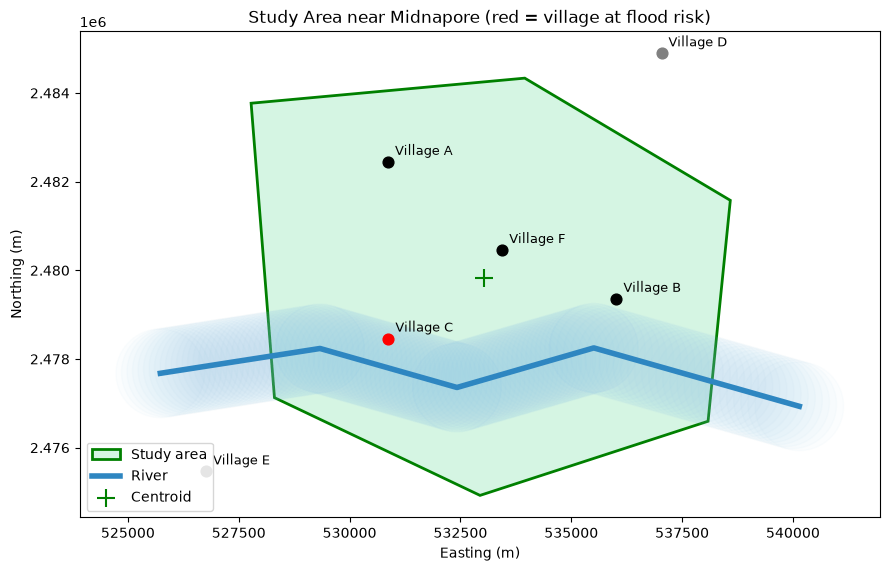

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))

xs, ys = zip(*(area_xy + area_xy[:1]))
ax.fill(xs, ys, color="#d5f5e3", edgecolor="green", linewidth=2, label="Study area")

rx, ry = zip(*river_xy)
ax.plot(rx, ry, color="#2e86c1", linewidth=4, label="River")

# Draw the 1 km buffer approximately, as circles of points around the river
for (x1, y1), (x2, y2) in zip(river_xy, river_xy[1:]):
    for t in np.linspace(0, 1, 30):
        circle = plt.Circle((x1 + t * (x2 - x1), y1 + t * (y2 - y1)), BUFFER_M, color="#85c1e9", alpha=0.03)
        ax.add_patch(circle)

for name, (x, y) in village_xy.items():
    inside = point_in_polygon((x, y), area_xy)
    colour = "red" if name in at_risk else ("black" if inside else "gray")
    ax.scatter(x, y, color=colour, s=60, zorder=3)
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9)

cx, cy = polygon_centroid(area_xy)
ax.scatter(cx, cy, marker="+", s=150, color="green", label="Centroid")
ax.set_aspect("equal")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title("Study Area near Midnapore (red = village at flood risk)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## **Step 8: Saving the Result as GeoJSON**
GeoJSON must use **latitude/longitude** (EPSG:4326), so we save the original coordinates, and add our results as **properties**.

In [10]:
features = [{
    "type": "Feature",
    "geometry": {"type": "Polygon", "coordinates": [[[lon, lat] for lat, lon in study_area + study_area[:1]]]},
    "properties": {"name": "Study area", "area_ha": round(area_m2 / 1e4, 1)},
}, {
    "type": "Feature",
    "geometry": {"type": "LineString", "coordinates": [[lon, lat] for lat, lon in river]},
    "properties": {"name": "Kangsabati (part)", "length_km": round(line_length(river_xy) / 1000, 2)},
}]
for name, (lat, lon) in villages.items():
    features.append({
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [lon, lat]},
        "properties": {"name": name,
                       "inside_study_area": point_in_polygon(village_xy[name], area_xy),
                       "distance_to_river_m": round(point_to_line(village_xy[name], river_xy)),
                       "flood_risk": name in at_risk},
    })

with open("midnapore_study.geojson", "w") as f:
    json.dump({"type": "FeatureCollection", "features": features}, f, indent=1)
print("Saved", len(features), "features. Open midnapore_study.geojson in QGIS to see them on a real map.")

Saved 8 features. Open midnapore_study.geojson in QGIS to see them on a real map.


In [11]:
# Quick question
# A horizontal ray from a point crosses a polygon boundary 3 times. Is the point inside or outside?